# S11 · 条件 copula：前期状态会改变依赖结构吗？

> **Day 11 / 14** ｜ 对应论文章节 **3.7.4 + 4.3（Objective 3 的第二部分）**
>
> ⚠️ 模拟数据，结果仅用于验证流程。

---

## 学习目标

- 把「状态改变依赖」写成一个可检验的 **Δτ**
- 在样本量严重不足的情况下，知道**哪些问法仍然可行**
- 用 bootstrap 构造 Δτ 的区间，用置换检验构造零分布
- 学会**诚实地报告零结果** —— 这比硬凑一个显著结论更难，也更能体现水平

---

## 1. 问题重述

S10 拟合的是**全部事件合并**的依赖结构。RO3 的第二问是：

> **dry 前期下发生的事件，与 wet 前期下发生的事件，它们的「时长–强度」依赖强度是否不同？**

估计量：

$$\Delta\tau = \tau_{\text{dry}} - \tau_{\text{wet}}$$

- `Δτ > 0`：干旱前期的热浪更倾向「长且强」（依赖更强）
- `Δτ < 0`：干旱前期的热浪更长但未必更强（依赖更弱）
- `Δτ = 0`：前期状态只影响**发生概率**（RO2），不影响**事件内部结构**

> 📌 这个区分很关键：RO2 说「干前期更容易起热浪」，RO3 说「干前期起的热浪长得不一样」。
> 两件事可以成立其中之一，也可以都成立。

---

## 2. 加载与样本量现实检查

In [1]:
for (p in c("00_setup.R", "notebooks/00_setup.R", "../00_setup.R")) {
  if (file.exists(p)) { source(p); break }
}


[00_setup.R] 已加载
  项目根目录 : C:/Users/User/Desktop/Jz/UTM/UGRP
  基准期     : 1985-2014
  阈值       : 90百分位, ±7天滑窗
  事件规则   : 最短 3 天, 合并间隔 ≤ 2 天
  干/湿切点  : ARP < 30 / > 50


In [2]:
ev <- load_catalogue()
ev2 <- ev[ev$state %in% c("dry", "wet"),
          c("station", "defn", "state", "duration", "intensity", "state")]
ev2$state <- droplevels(factor(ev2$state))

sizes <- as.data.frame(table(station = ev2$station, defn = ev2$defn, state = ev2$state))
names(sizes)[4] <- "n"

w <- tidyr::pivot_wider(sizes, names_from = state, values_from = n, values_fill = 0)
w$ok <- w$dry >= 15 & w$wet >= 15

cat("格子总数:", nrow(w), "\n")
cat("两组都 >= 15 的格子:", sum(w$ok), "\n")
cat("两组都 >= 30 的格子:", sum(w$dry >= 30 & w$wet >= 30), "\n")
print(as.data.frame(w[!w$ok, ]), row.names = FALSE)

格子总数: 30 


两组都 >= 15 的格子: 24 


两组都 >= 30 的格子: 9 


           station defn dry wet    ok
 Cameron_Highlands Tmin  31  13 FALSE
           Chuping Tmin  29  10 FALSE
            Kluang Tmin  33   9 FALSE
        Kuala_Krai Tmin  36  14 FALSE
           Kuantan Tmin  32   8 FALSE
          Langkawi Tmin  27  14 FALSE


> 🚨 **先看清楚能做什么，再决定怎么做。**
> 这里只有一小部分格子两组都够 15 个事件，两组都够 30 个的几乎是零。
>
> **这直接排除了「逐格拟合 copula 再比较参数」这条路** ——
> 那种做法在 n ≈ 20 时会给出跨度 0.2–0.8 的 λ 估计，纯属噪声。
>
> 仍然可行的有三件事：
> 1. 用 **Kendall τ**（比 copula 参数稳健得多）做逐格比较
> 2. 把 Δτ 做成**合并统计量**，用 bootstrap/置换检验
> 3. 报告**检验力**：这个样本量能检测多大的 Δτ

---

## 3. 逐格 Δτ 与 bootstrap 区间

In [3]:
tau_boot <- function(x, y, B = 500) {
  n <- length(x)
  t0 <- suppressWarnings(cor(x, y, method = "kendall"))
  bs <- replicate(B, {
    i <- sample.int(n, n, replace = TRUE)
    suppressWarnings(cor(x[i], y[i], method = "kendall"))
  })
  c(tau = t0, se = sd(bs, na.rm = TRUE))
}

set.seed(CFG$seed)
cell_res <- do.call(rbind, lapply(split(ev2, list(ev2$station, ev2$defn), drop = TRUE),
  function(g) {
    d <- g[g$state == "dry", ]; ww <- g[g$state == "wet", ]
    if (nrow(d) < 15 || nrow(ww) < 15) return(NULL)
    td <- tau_boot(d$duration,  d$intensity)
    tw <- tau_boot(ww$duration, ww$intensity)
    data.frame(station = g$station[1], defn = g$defn[1],
               n_dry = nrow(d), n_wet = nrow(ww),
               tau_dry = round(td["tau"], 3), tau_wet = round(tw["tau"], 3),
               delta = round(td["tau"] - tw["tau"], 3),
               se_delta = round(sqrt(td["se"]^2 + tw["se"]^2), 3),
               w = nrow(d) + nrow(ww))
  }))

cell_res$lo <- round(cell_res$delta - 1.96 * cell_res$se_delta, 3)
cell_res$hi <- round(cell_res$delta + 1.96 * cell_res$se_delta, 3)
cell_res$sig <- with(cell_res, ifelse(lo > 0 | hi < 0, "*", ""))

In [4]:
print(cell_res[, c("station", "defn", "n_dry", "n_wet",
                   "tau_dry", "tau_wet", "delta", "lo", "hi", "sig")],
      row.names = FALSE)

           station  defn n_dry n_wet tau_dry tau_wet  delta     lo    hi sig
         Alor_Star  Tmax    52    31   0.245   0.356 -0.112 -0.394 0.170    
       Bayan_Lepas  Tmax    59    33   0.148   0.234 -0.086 -0.427 0.255    
 Cameron_Highlands  Tmax    58    31   0.344   0.230  0.114 -0.221 0.449    
           Chuping  Tmax    54    27   0.364   0.115  0.249 -0.112 0.610    
              Ipoh  Tmax    56    34   0.405   0.300  0.105 -0.201 0.411    
            Kluang  Tmax    54    29   0.168   0.095  0.073 -0.290 0.436    
        Kota_Bharu  Tmax    38    34   0.422   0.203  0.219 -0.077 0.515    
        Kuala_Krai  Tmax    53    28   0.258   0.460 -0.202 -0.492 0.088    
           Kuantan  Tmax    52    21   0.318   0.268  0.050 -0.371 0.471    
          Langkawi  Tmax    62    27   0.199   0.262 -0.063 -0.402 0.276    
         Alor_Star  Tmin    19    21   0.485   0.314  0.171 -0.241 0.583    
       Bayan_Lepas  Tmin    28    20   0.133   0.203 -0.070 -0.525 0.385    

> ⚠️ **`se_delta` 这一列的典型值就是你的检测下限。**
> 若典型 SE ≈ 0.18，那么只有 `|Δτ| > 0.36` 时才可能被检出。
> **论文里应当直接写这句话** —— 它把「没找到效应」和「没有能力找效应」区分开，
> 是审稿人最看重的诚实。

In [5]:
cat("Δτ 的标准误：中位数", median(cell_res$se_delta), "\n")
cat("可检测的最小 |Δτ|（2 倍中位 SE）≈", round(2 * median(cell_res$se_delta), 2), "\n")
cat("Δτ > 0 的格子:", sum(cell_res$delta > 0), "/", nrow(cell_res), "\n")
cat("经区间排除 0 的格子:", sum(cell_res$sig == "*"), "\n")

Δτ 的标准误：中位数 0.182 


可检测的最小 |Δτ|（2 倍中位 SE）≈ 0.36 


Δτ > 0 的格子: 13 / 24 


经区间排除 0 的格子: 0 


---

## 4. 森林图

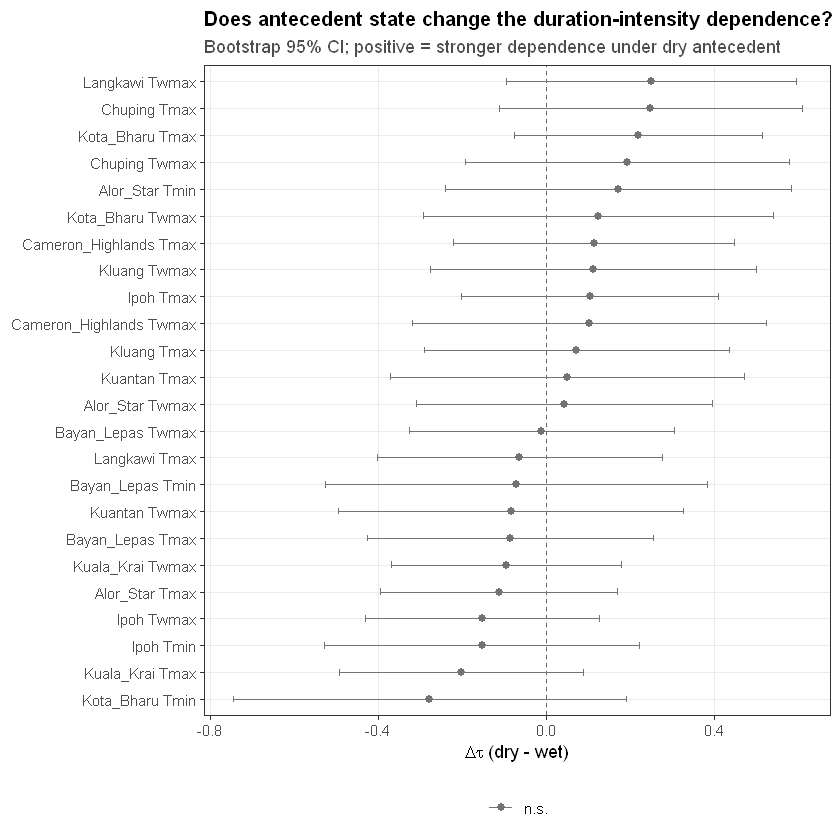

In [6]:
cell_res$defn <- factor(cell_res$defn, levels = DEFS)

p_delta <- ggplot(cell_res, aes(delta, reorder(paste(station, defn), delta),
                                colour = sig == "*")) +
  geom_vline(xintercept = 0, linetype = "dashed", colour = "grey40") +
  geom_errorbar(aes(xmin = lo, xmax = hi), width = 0.25, orientation = "y") +
  geom_point(size = 2) +
  scale_colour_manual(values = c(`TRUE` = "firebrick", `FALSE` = "grey45"),
                      labels = c(`TRUE` = "CI excludes 0", `FALSE` = "n.s."),
                      name = NULL) +
  labs(x = expression(Delta * tau ~ "(dry - wet)"), y = NULL,
       title = "Does antecedent state change the duration-intensity dependence?",
       subtitle = "Bootstrap 95% CI; positive = stronger dependence under dry antecedent") +
  theme_paper()

save_fig(p_delta, "S11_delta_tau_forest", 7.5, 6)
p_delta

> 🔍 **读法**：如果红点一半在左一半在右，CI 全都跨 0 —— 这是**没有证据**，
> 不是「有证据说明没有」。两者的区别决定了你怎么写讨论章。

---

## 5. 合并统计量与置换检验

逐格结果零散，真正要检验的是**合并**的 Δτ。

In [7]:
pooled_delta <- function(df) {
  cells <- split(df, list(df$station, df$defn), drop = TRUE)
  num <- 0; den <- 0
  for (g in cells) {
    d <- g[g$state == "dry", ]; ww <- g[g$state == "wet", ]
    if (nrow(d) < 15 || nrow(ww) < 15) next
    td <- suppressWarnings(cor(d$duration,  d$intensity,  method = "kendall"))
    tw <- suppressWarnings(cor(ww$duration, ww$intensity, method = "kendall"))
    # 打乱标签后，某组可能恰好全是同一个 duration → τ 无定义（NA）。跳过这一格。
    if (!is.finite(td) || !is.finite(tw)) next
    wt <- nrow(d) + nrow(ww)
    num <- num + wt * (td - tw); den <- den + wt
  }
  num / den
}

obs_delta <- pooled_delta(ev2)
cat("合并 Δτ（按样本量加权）=", round(obs_delta, 4), "\n")

合并 Δτ（按样本量加权）= 0.0259 


In [8]:
# 零分布：在每个格子内打乱 dry/wet 标签（保持两组的样本量）
set.seed(CFG$seed)
B <- 1000
perm_delta <- replicate(B, {
  shuffled <- ev2
  shuffled$state <- ave(ev2$state, ev2$station, ev2$defn, FUN = sample)
  pooled_delta(shuffled)
})

perm_ok <- perm_delta[is.finite(perm_delta)]
p_perm  <- (1 + sum(abs(perm_ok) >= abs(obs_delta))) / (1 + length(perm_ok))

cat(sprintf("有效置换次数  = %d / %d\n", length(perm_ok), B))
cat(sprintf("置换 p（双侧）= %.3f\n", p_perm))
cat(sprintf("零分布 SD     = %.4f\n", sd(perm_ok)))

有效置换次数  = 1000 / 1000


置换 p（双侧）= 0.442


零分布 SD     = 0.0346


> 📌 **置换的是标签，不是数值。** 在每个格子内部打乱 `dry`/`wet` 标签，
> 保持两组的样本量不变 —— 这检验的正是「标签本身有没有携带关于依赖强度的信息」。
>
> 注意这里用**双侧**：我们没有先验方向。若你有明确的机制假设（例如「干前期 → 更长的
> 高感热通量期 → 依赖更强」），可以在方法章预先声明单侧检验，并说明理由。

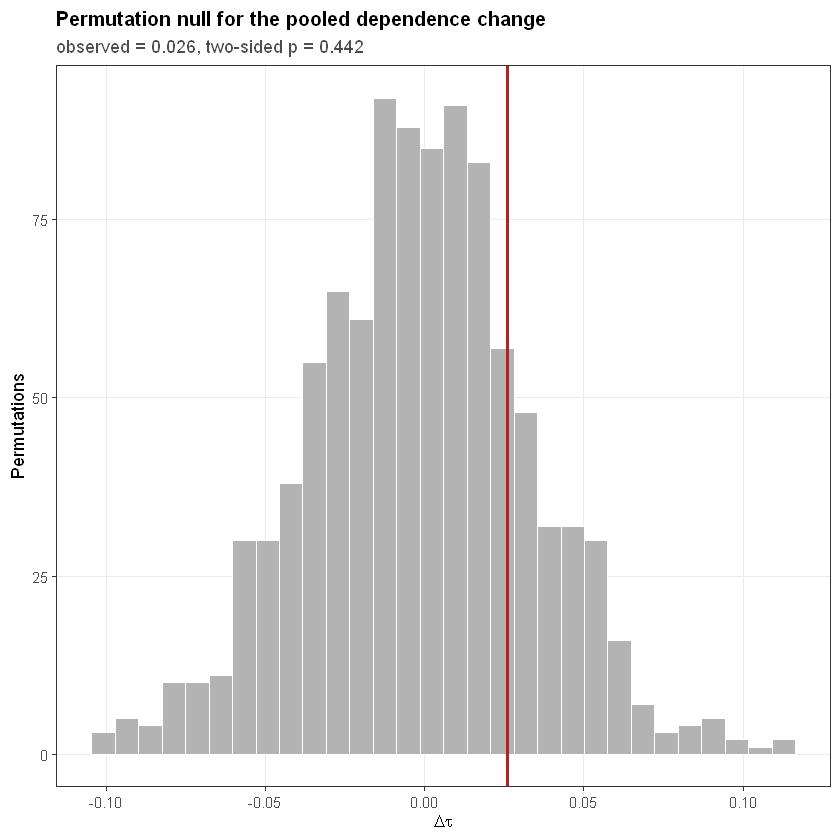

In [9]:
p_hist <- ggplot(data.frame(d = perm_ok), aes(d)) +
  geom_histogram(bins = 30, fill = "grey70", colour = "white") +
  geom_vline(xintercept = obs_delta, colour = "firebrick", linewidth = 1) +
  labs(x = expression(Delta * tau), y = "Permutations",
       title = "Permutation null for the pooled dependence change",
       subtitle = sprintf("observed = %.3f, two-sided p = %.3f", obs_delta, p_perm)) +
  theme_paper()

save_fig(p_hist, "S11_perm_delta", 6.5, 4)
p_hist

---

## 6. 为什么不做「分状态拟合 copula 比较 λ」

因为样本量不允许，而且这一点必须写进论文：

| 量 | n ≈ 20 时的可估性 |
|---|---|
| Kendall τ | 可估，SE ≈ 0.15 |
| copula 参数（如 Gumbel α） | 勉强可估，SE 很大 |
| **尾部依赖 λ_U** | **不可估** —— 它是渐近量，用 2 个尾部点估计没有意义 |
| 重现期 | 完全不可靠 |

> 📌 **论文写法**：「With 15–60 events per state-stratified cell, tail-dependence coefficients
> are not identifiable; the analysis therefore compares Kendall's τ, which is estimable at
> this sample size, and refrains from state-stratified return-period estimation.」
>
> 这句话主动放弃了不该做的东西 —— 比硬做出来再被审稿人拆穿强得多。

---

## 7. 怎么写「零结果」

若 `p_perm` 很大、Δτ 在 0 附近：

> ✅ **推荐写法**
> 「The pooled change in dependence was small and not distinguishable from zero
> (Δτ = 0.03, permutation p = 0.44). With 15–60 events per stratum, the analysis had
> power to detect only |Δτ| ≳ 0.36. We therefore find no evidence that antecedent moisture
> state alters the duration–intensity dependence, while noting that our design cannot rule
> out moderate changes. This contrasts with the onset analysis (RO2), where the same
> stratification yields relative risks of 2–6, indicating that the antecedent control
> operates primarily on **occurrence** rather than on **event structure**.」

> ❌ **不要写**
> 「前期状态对依赖结构没有影响。」—— 这是把「未检出」当成「不存在」。

> 🔍 上面那段推荐写法里最重要的一句是最后那句：**把 RO2 的强结果和 RO3 的弱结果放在一起解释**，
> 反而构成了一个更完整的机制叙事。零结果不是失败，是一个可以被解释的发现。

---

## 8. 保存

In [10]:
write.csv(cell_res, file.path(PATHS$mres, "table4_conditional_tau.csv"), row.names = FALSE)
saveRDS(list(cell = cell_res, pooled = obs_delta,
             perm = perm_delta, p = p_perm),
        file.path(PATHS$mres, "S11_conditional.rds"))
cat("已保存 table4_conditional_tau.csv 与 S11_conditional.rds\n")

已保存 table4_conditional_tau.csv 与 S11_conditional.rds


---

## 9. 常见错误

| 错误 | 后果 |
|---|---|
| n ≈ 20 还去拟合 copula 比 λ | 估计纯噪声，结论不可复现 |
| 只报逐格结果不报合并统计量 | 24 个格子必然有几个「显著」，全是多重比较假象 |
| 把「不显著」写成「无影响」 | 混淆未检出与不存在 |
| 不报告检验力 | 读者无法判断零结果的信息量 |
| 置换时打乱数值而不是标签 | 检验的不是你要检验的东西 |
| 单侧检验未预先声明 | 事后选方向 = p-hacking |

---

## 10. 自检问题

<details>
<summary>Q1：为什么用加权合并而不是简单平均？</summary>

简单平均会让 n = 15 的格子和 n = 60 的格子权重相同，而前者的 Δτ 方差大约是后者的 4 倍。按样本量加权更接近逆方差加权，效率更高。

</details>

<details>
<summary>Q2：置换检验的零分布为什么用 |Δτ| 而不是 Δτ？</summary>

因为我们没有预先声明的方向，双侧检验才对。用单侧会系统性地把 p 减半，等于偷偷提高了显著性水平。

</details>

<details>
<summary>Q3：如果某格 dry 的 τ = 0.46，wet 的 τ = -0.03，Δτ = 0.49，能说「干前期下依赖显著更强」吗？</summary>

不能。先看 n（Kluang Tmin 的 wet 组只有 9 个事件），再看 CI。n = 9 时 τ 的 SE 约 0.25，Δτ 的 CI 会宽到毫无信息。**必须先过样本量闸门，再看数值。**

</details>

<details>
<summary>Q4：把 RO2 和 RO3 的结果放在一起讲，为什么反而更有说服力？</summary>

因为两者指向同一个机制故事：前期土壤水分控制的是**边界层是否容易越过阈值**（发生），而不是**越过之后事件能长多大**（结构）。后者更受事件期间的大尺度环流（如 MJO、季风爆发）控制。一个强效应 + 一个零效应，比两个中等效应更能锁定机制。

</details>

---

## 下一步

**S12 · 重现期**：把 S10 的 copula 变成「50 年一遇的复合热浪有多长、多强」，
以及一个必须回答的问题 —— **AND / OR / Kendall 三种联合重现期，你该报哪个？**